DATASET INFORMATION
Dataset Shape: (45789, 16)

First 5 Records:
  country_code country_iso2  country  is_country_group poverty_status_code  \
0           AL           AL  Albania             False                A_60   
1           AL           AL  Albania             False                A_60   
2           AL           AL  Albania             False                A_60   
3           AL           AL  Albania             False                A_60   
4           AL           AL  Albania             False                A_60   

  poverty_status age_group_code age_group sex_code      sex  period  \
0      Above 60%          TOTAL     Total        F  Females    2017   
1      Above 60%          TOTAL     Total        F  Females    2018   
2      Above 60%          TOTAL     Total        F  Females    2019   
3      Above 60%          TOTAL     Total        F  Females    2020   
4      Above 60%          TOTAL     Total        F  Females    2021   

         date  year  overburden_rate_pc

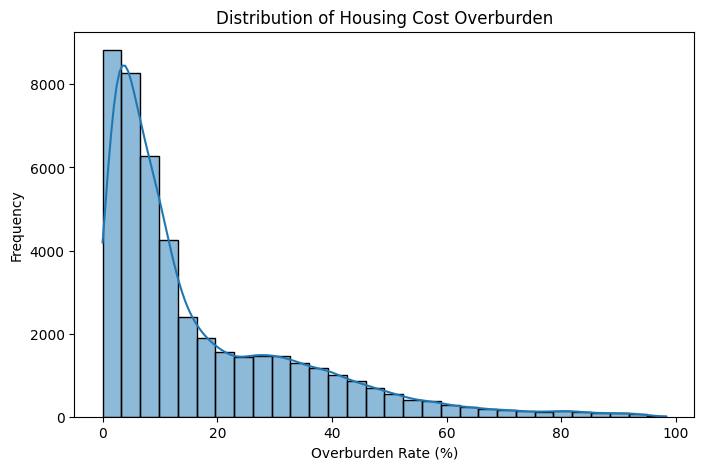

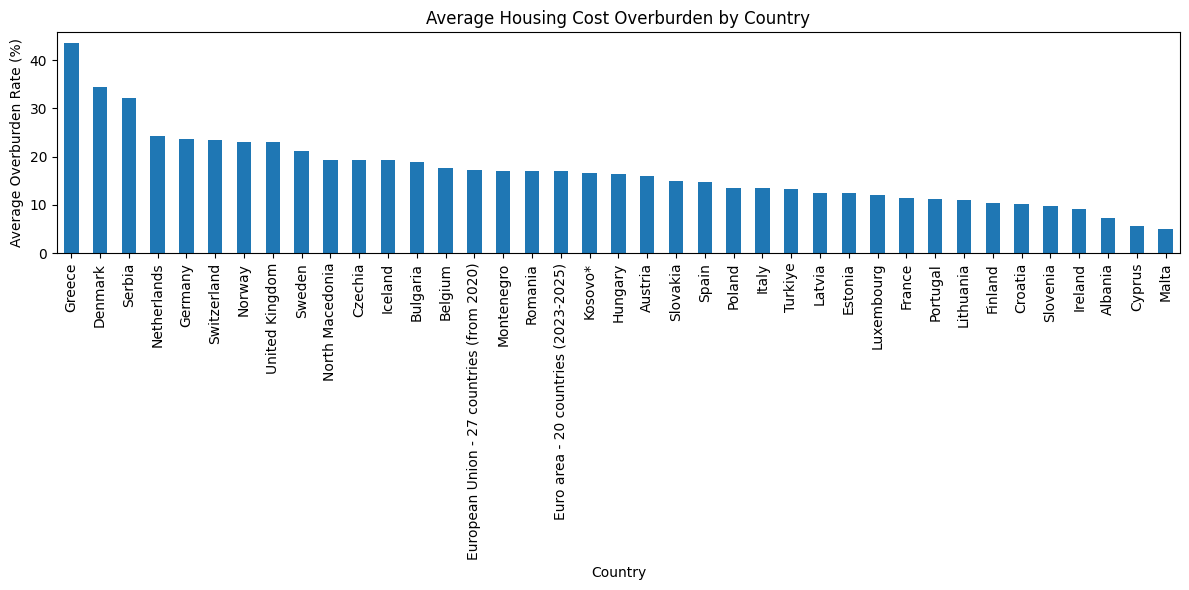

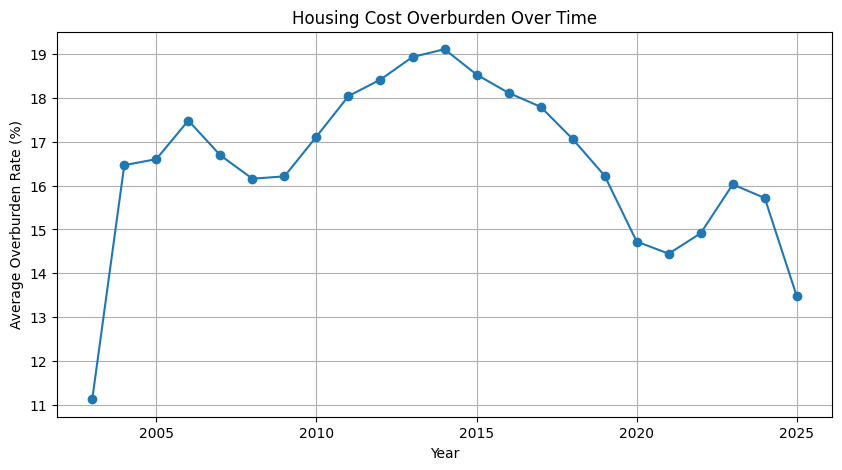


LINEAR REGRESSION
Mean Absolute Error: 5.885210877375482
Mean Squared Error: 68.54965729648274
Root Mean Squared Error: 8.279472042134254
R2 Score: 0.7726973824410281


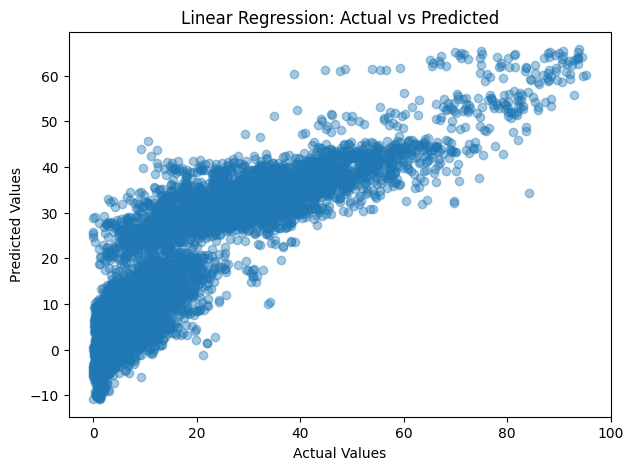


DECISION TREE REGRESSION
Mean Absolute Error: 5.039968648639225
Mean Squared Error: 60.679560470549745
Root Mean Squared Error: 7.789708625523149
R2 Score: 0.7987936997608948


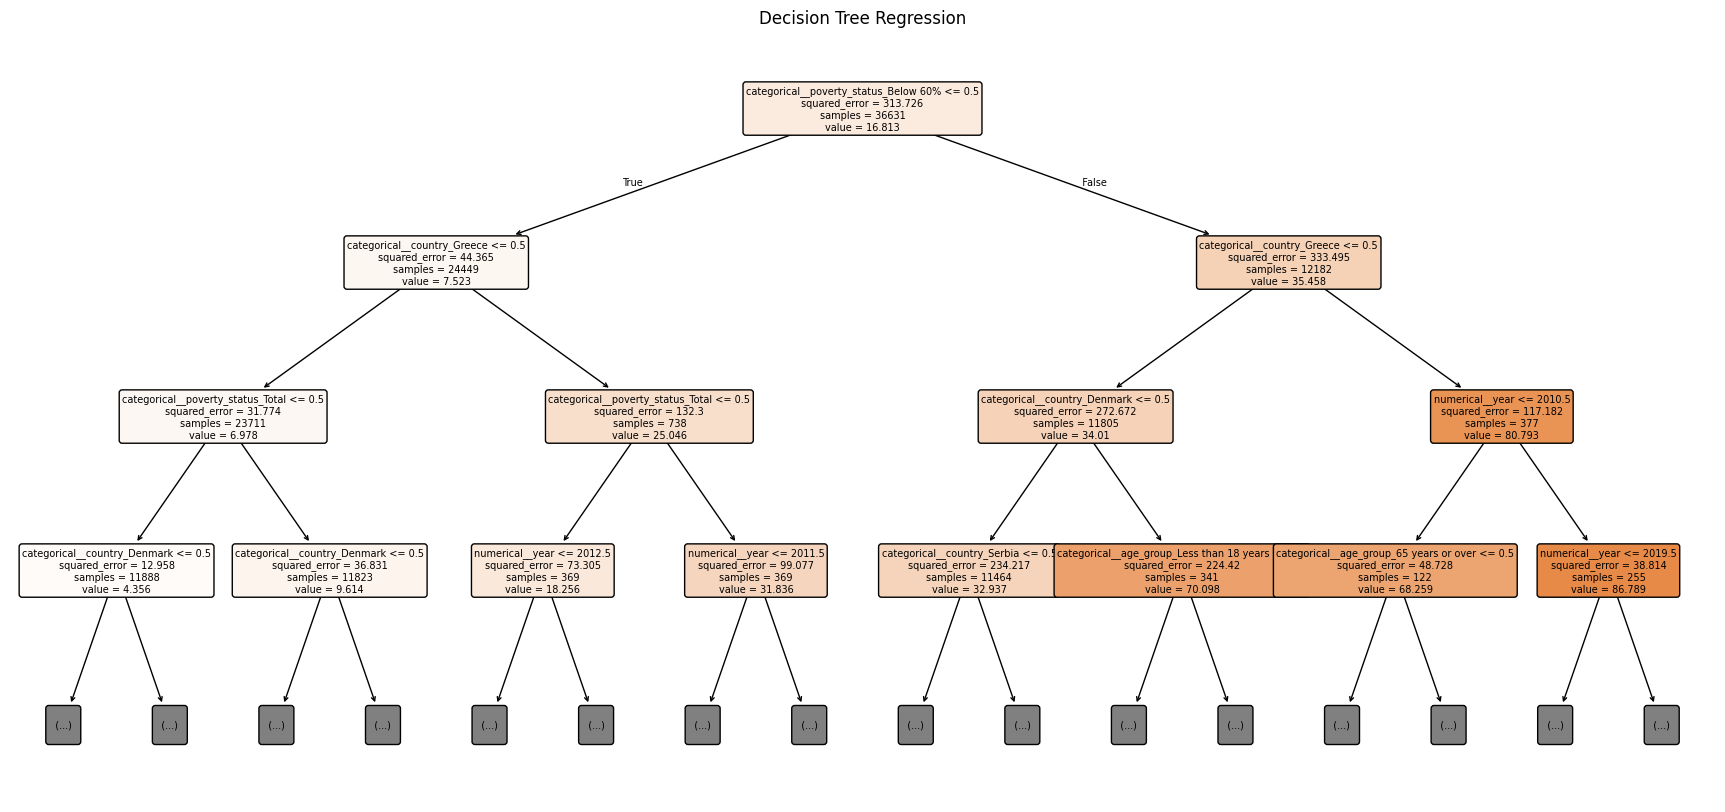


DECISION TREE CLASSIFICATION
Classification Accuracy: 0.8181917449224722

Classification Report:
              precision    recall  f1-score   support

        High       0.92      0.90      0.91      3045
         Low       0.82      0.80      0.81      3093
      Medium       0.72      0.75      0.73      3020

    accuracy                           0.82      9158
   macro avg       0.82      0.82      0.82      9158
weighted avg       0.82      0.82      0.82      9158



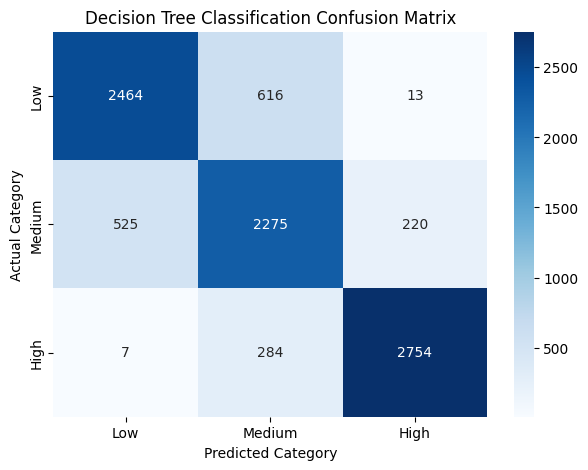


K-MEANS CLUSTERING

Country-Level Features:
          mean_overburden  median_overburden  std_overburden  max_overburden  \
country                                                                        
Albania          7.359637               3.80        7.962880            34.5   
Austria         15.998124               7.15       17.108628            74.6   
Belgium         17.739683               9.60       16.680628            72.9   
Bulgaria        18.963413              12.90       15.703352            70.7   
Croatia         10.284722               5.10       11.296909            53.4   

          min_overburden  number_of_records  first_year  last_year  
country                                                             
Albania              0.3                441        2017       2023  
Austria              0.1               1386        2004       2025  
Belgium              0.7               1386        2004       2025  
Bulgaria             0.0               1260      

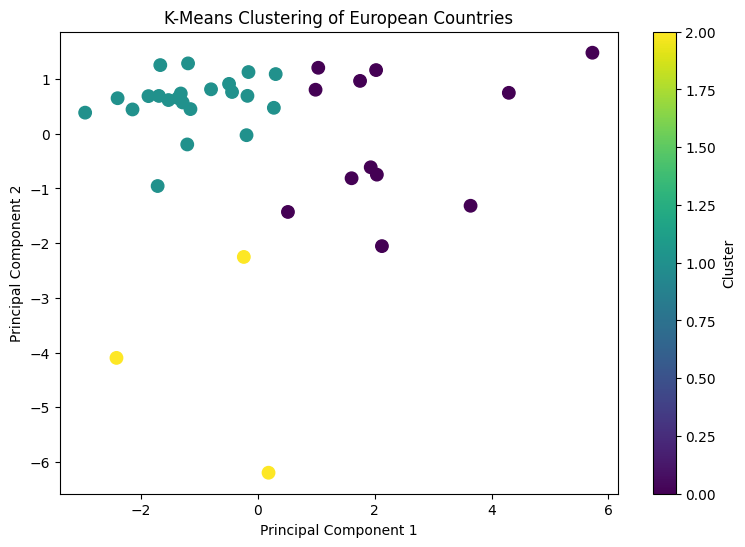


Average Housing Overburden by Cluster:
Cluster
0    25.575215
1    12.593977
2    13.734121
Name: mean_overburden, dtype: float64

MODEL COMPARISON
                  Algorithm       MAE      RMSE  R2 Score
0         Linear Regression  5.885211  8.279472  0.772697
1  Decision Tree Regression  5.039969  7.789709  0.798794


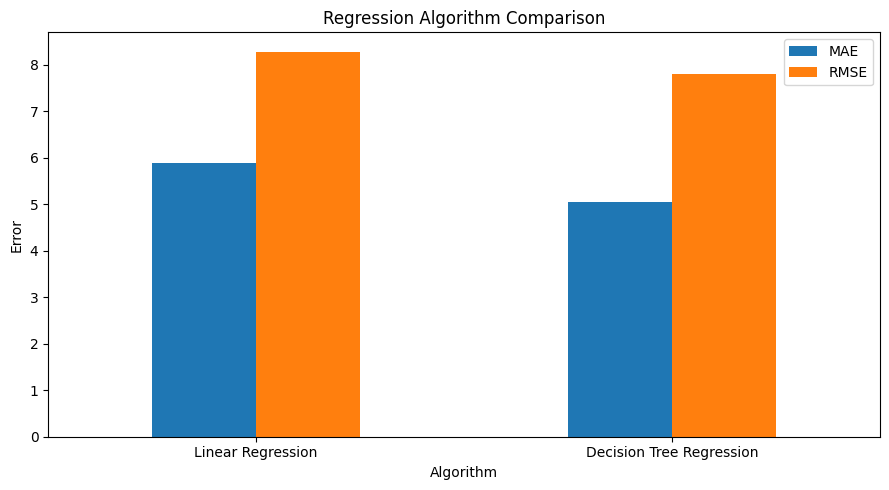


PROJECT COMPLETED SUCCESSFULLY
Saved files:
1. model_comparison.csv
2. country_clustering_results.csv


In [1]:

# ============================================================
# MACHINE LEARNING PROJECT
# European Housing Cost Overburden Analysis
#
# Algorithms:
# 1. Linear Regression
# 2. Decision Tree Regression
# 3. Decision Tree Classification
# 4. K-Means Clustering
# ============================================================

# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    silhouette_score
)

from sklearn.decomposition import PCA
from sklearn.tree import plot_tree

import warnings
warnings.filterwarnings("ignore")


# STEP 2: LOAD DATASET

df = pd.read_csv("/kaggle/input/datasets/joeyawsyn/dataset/european_housing_cost_overburden.csv")

print("DATASET INFORMATION")
print("===================")

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
print(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Description:")
print(df.describe())


# STEP 3: DATA PREPROCESSING

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing target values
df = df.dropna(subset=["overburden_rate_pct"])

# Remove unnecessary columns
# Codes and dates are redundant with the descriptive columns/year.
# Flag columns are mostly missing and are not used as predictors.

df = df.drop(
    columns=[
        "country_code",
        "country_iso2",
        "poverty_status_code",
        "age_group_code",
        "sex_code",
        "period",
        "date",
        "flag",
        "flag_meaning"
    ],
    errors="ignore"
)

# Display cleaned dataset

print("\nCleaned Dataset Shape:")
print(df.shape)

print("\nRemaining Missing Values:")
print(df.isnull().sum())


# STEP 4: EXPLORATORY DATA ANALYSIS

# Distribution of housing overburden

plt.figure(figsize=(8, 5))

sns.histplot(
    df["overburden_rate_pct"],
    bins=30,
    kde=True
)

plt.title("Distribution of Housing Cost Overburden")
plt.xlabel("Overburden Rate (%)")
plt.ylabel("Frequency")
plt.show()


# Average housing overburden by country

country_avg = (
    df.groupby("country")["overburden_rate_pct"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

country_avg.plot(kind="bar")

plt.title("Average Housing Cost Overburden by Country")
plt.xlabel("Country")
plt.ylabel("Average Overburden Rate (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


# Housing overburden over the years

year_avg = df.groupby("year")["overburden_rate_pct"].mean()

plt.figure(figsize=(10, 5))

year_avg.plot(marker="o")

plt.title("Housing Cost Overburden Over Time")
plt.xlabel("Year")
plt.ylabel("Average Overburden Rate (%)")
plt.grid(True)
plt.show()


# STEP 5: SUPERVISED LEARNING
# PROBLEM:
# Predict housing cost overburden percentage.


# Select input features

features = [
    "country",
    "is_country_group",
    "poverty_status",
    "age_group",
    "sex",
    "year"
]

X = df[features]

# Target variable

y = df["overburden_rate_pct"]


# Identify categorical and numerical columns

categorical_features = [
    "country",
    "poverty_status",
    "age_group",
    "sex"
]

numerical_features = [
    "year",
    "is_country_group"
]


# Convert categorical values into numbers

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)


# Split dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


# ============================================================
# ALGORITHM 1: LINEAR REGRESSION
# ============================================================

print("\n================================")
print("LINEAR REGRESSION")
print("================================")

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

# Train model

linear_model.fit(X_train, y_train)

# Predict

linear_predictions = linear_model.predict(X_test)

# Evaluate model

linear_mae = mean_absolute_error(
    y_test, linear_predictions
)

linear_mse = mean_squared_error(
    y_test, linear_predictions
)

linear_rmse = np.sqrt(linear_mse)

linear_r2 = r2_score(
    y_test, linear_predictions
)

print("Mean Absolute Error:", linear_mae)
print("Mean Squared Error:", linear_mse)
print("Root Mean Squared Error:", linear_rmse)
print("R2 Score:", linear_r2)


# Actual vs Predicted graph

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    linear_predictions,
    alpha=0.4
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Linear Regression: Actual vs Predicted")

plt.show()


# ============================================================
# ALGORITHM 2: DECISION TREE REGRESSION
# ============================================================

print("\n================================")
print("DECISION TREE REGRESSION")
print("================================")

tree_regressor = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=8,
                random_state=42
            )
        )
    ]
)

# Train model

tree_regressor.fit(X_train, y_train)

# Predictions

tree_predictions = tree_regressor.predict(X_test)

# Evaluation

tree_mae = mean_absolute_error(
    y_test, tree_predictions
)

tree_mse = mean_squared_error(
    y_test, tree_predictions
)

tree_rmse = np.sqrt(tree_mse)

tree_r2 = r2_score(
    y_test, tree_predictions
)

print("Mean Absolute Error:", tree_mae)
print("Mean Squared Error:", tree_mse)
print("Root Mean Squared Error:", tree_rmse)
print("R2 Score:", tree_r2)


# Visualize Decision Tree

tree_model = tree_regressor.named_steps["model"]

feature_names = (
    tree_regressor
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

plt.figure(figsize=(22, 10))

plot_tree(
    tree_model,
    feature_names=feature_names,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=7
)

plt.title("Decision Tree Regression")
plt.show()


# ============================================================
# ALGORITHM 3: DECISION TREE CLASSIFICATION
# ============================================================

print("\n================================")
print("DECISION TREE CLASSIFICATION")
print("================================")

# Create three categories using target-value tertiles.
# These are dataset-derived categories, not official
# European housing classifications.

df["overburden_category"] = pd.qcut(
    df["overburden_rate_pct"],
    q=3,
    labels=["Low", "Medium", "High"]
)

# Input and output

X_class = df[features]

y_class = df["overburden_category"]

# Split data

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)


# Create classification model

tree_classifier = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeClassifier(
                max_depth=8,
                random_state=42
            )
        )
    ]
)

# Train classifier

tree_classifier.fit(X_train_c, y_train_c)

# Predict categories

class_predictions = tree_classifier.predict(X_test_c)

# Evaluate

accuracy = accuracy_score(
    y_test_c,
    class_predictions
)

print("Classification Accuracy:", accuracy)

print("\nClassification Report:")

print(
    classification_report(
        y_test_c,
        class_predictions
    )
)


# Confusion Matrix

cm = confusion_matrix(
    y_test_c,
    class_predictions,
    labels=["Low", "Medium", "High"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Decision Tree Classification Confusion Matrix")

plt.show()


# ============================================================
# STEP 6: UNSUPERVISED LEARNING
# ALGORITHM 4: K-MEANS CLUSTERING
# ============================================================

print("\n================================")
print("K-MEANS CLUSTERING")
print("================================")

# Exclude country groups because we want to
# compare individual countries.

individual_countries = df[
    df["is_country_group"] == False
].copy()


# Create country-level features

country_features = (
    individual_countries
    .groupby("country")
    .agg(
        mean_overburden=("overburden_rate_pct", "mean"),
        median_overburden=("overburden_rate_pct", "median"),
        std_overburden=("overburden_rate_pct", "std"),
        max_overburden=("overburden_rate_pct", "max"),
        min_overburden=("overburden_rate_pct", "min"),
        number_of_records=("overburden_rate_pct", "count"),
        first_year=("year", "min"),
        last_year=("year", "max")
    )
    .fillna(0)
)

print("\nCountry-Level Features:")

print(country_features.head())


# Standardize the data

scaler = StandardScaler()

scaled_data = scaler.fit_transform(
    country_features
)


# Find the best number of clusters using silhouette score

silhouette_results = {}

for k in range(2, min(7, len(country_features))):

    temp_model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    temp_labels = temp_model.fit_predict(
        scaled_data
    )

    score = silhouette_score(
        scaled_data,
        temp_labels
    )

    silhouette_results[k] = score

    print(
        "Clusters:", k,
        "| Silhouette Score:", score
    )


# Select the best k

best_k = max(
    silhouette_results,
    key=silhouette_results.get
)

print("\nBest Number of Clusters:", best_k)


# Train final K-Means model

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(
    scaled_data
)

country_features["Cluster"] = clusters

print("\nCountry Cluster Results:")

print(
    country_features[
        ["mean_overburden", "Cluster"]
    ].sort_values("Cluster")
)


# Visualize clusters using PCA

pca = PCA(n_components=2)

pca_data = pca.fit_transform(
    scaled_data
)

plt.figure(figsize=(9, 6))

plt.scatter(
    pca_data[:, 0],
    pca_data[:, 1],
    c=clusters,
    cmap="viridis",
    s=80
)

plt.title("K-Means Clustering of European Countries")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")

plt.show()


# Display average overburden per cluster

cluster_summary = (
    country_features
    .groupby("Cluster")["mean_overburden"]
    .mean()
)

print("\nAverage Housing Overburden by Cluster:")

print(cluster_summary)


# ============================================================
# STEP 7: COMPARE SUPERVISED MODELS
# ============================================================

print("\n================================")
print("MODEL COMPARISON")
print("================================")

comparison = pd.DataFrame({
    "Algorithm": [
        "Linear Regression",
        "Decision Tree Regression"
    ],
    "MAE": [
        linear_mae,
        tree_mae
    ],
    "RMSE": [
        linear_rmse,
        tree_rmse
    ],
    "R2 Score": [
        linear_r2,
        tree_r2
    ]
})

print(comparison)


# Plot model comparison

comparison.set_index("Algorithm")[
    ["MAE", "RMSE"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Regression Algorithm Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ============================================================
# STEP 8: SAVE RESULTS
# ============================================================

comparison.to_csv(
    "model_comparison.csv",
    index=False
)

country_features.to_csv(
    "country_clustering_results.csv"
)

print("\n================================")
print("PROJECT COMPLETED SUCCESSFULLY")
print("================================")

print("Saved files:")
print("1. model_comparison.csv")
print("2. country_clustering_results.csv")
